# Pipeline Completo: ETL, EDA y Preprocesamiento de Imágenes de Placas Solares

Este notebook está estructurado de forma modular mediante funciones reutilizables:
1. **Extracción (Web Scraping con Selenium)**: Descarga opcional de imágenes adicionales limpias.
2. **Construcción del Dataset**: Almacenamiento eficiente mediante **rutas relativas** y lectura ligera de cabeceras (sin guardar objetos pesados en RAM).
3. **EDA (Análisis Exploratorio de Datos)**: Calidad del dato, balance de splits, distribuciones de resolución, outliers por IQR, correlaciones y visualización al vuelo.
4. **Preprocesamiento para Modelado**:
   - **Opción A (Machine Learning Clásico / Tabular)**: Extracción de descriptores visuales de color (RGB/HSV) y textura superficial + Escalado sin *data leakage*.
   - **Opción B (Deep Learning / PyTorch)**: `Dataset` y `DataLoaders` con redimensionado, *Data Augmentation* geométrico y normalización.

In [1]:
import os
import sys
import time
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_theme(style="whitegrid")

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}


## 1. Extracción con Selenium (Imágenes Extra)

In [2]:
from src.pixabay_scraper import scrape_extra_solar_images

# Descomentar si se desea volver a ejecutar la descarga:
try:
    scrape_extra_solar_images(output_dir=PROJECT_ROOT / "solar_panel_images" / "scraped", max_images=20, scrolls=4)
except Exception as exc:
    print(f"El scraper no se ejecutó por un problema del navegador: {exc}")
    print("Si no tienes Chrome/Chromium instalado, puedes omitir esta celda y seguir con el resto del proyecto.")


Abriendo https://pixabay.com/images/search/solar%20panel/...
Encontrada [1/20]: free photovoltaic system solar photo and picture...
Encontrada [2/20]: free solar panel photo and picture...
Encontrada [3/20]: free solar energy solar system photo and picture...
Encontrada [4/20]: free solar cell solar panel photo and picture...
Encontrada [5/20]: free solar system roof photo and picture...
Encontrada [6/20]: free photovoltaic system solar photo and picture...
Encontrada [7/20]: free photovoltaic solar photo and picture...
Encontrada [8/20]: free photovoltaic photovoltaic system photo and pi...
Encontrada [9/20]: free photovoltaic photovoltaic system photo and pi...
Encontrada [10/20]: free solar energy solar panels photo and picture...
Encontrada [11/20]: free solar power photo and picture...
Encontrada [12/20]: free solar panels photo and picture...
Encontrada [13/20]: free solar panels renewable energy vector and pict...
Encontrada [14/20]: free photovoltaic nature photo and picture...

## 2. Construcción del Dataset con Rutas Relativas y Metadatos

In [3]:
from src.solar_dataset import build_solar_dataframe


In [4]:
df = build_solar_dataframe(root_dir=PROJECT_ROOT)
df.head(10)


DataFrame creado y guardado en 'data/pvsoiling_dataframe.pkl' con 1714 filas.


,split,ruta_imagen,filename,extension,source,es_sucio,width,height,aspect_ratio,n_pixels,image_mode
0,train,solar_panel_images/PVSDL_DATASET/train/city_00...,city_0001_0.jpg,.jpg,pvdl_dataset,0,474,338,1.4024,160212,RGB
1,train,solar_panel_images/PVSDL_DATASET/train/city_00...,city_0002_0.jpg,.jpg,pvdl_dataset,0,537,387,1.3876,207819,RGB
2,train,solar_panel_images/PVSDL_DATASET/train/city_00...,city_0003_0.jpg,.jpg,pvdl_dataset,0,608,382,1.5916,232256,RGB
3,train,solar_panel_images/PVSDL_DATASET/train/city_00...,city_0004_0.jpg,.jpg,pvdl_dataset,0,562,362,1.5525,203444,RGB
4,train,solar_panel_images/PVSDL_DATASET/train/city_00...,city_0005_0.jpg,.jpg,pvdl_dataset,0,242,353,0.6856,85426,RGB
5,train,solar_panel_images/PVSDL_DATASET/train/city_00...,city_0007_0.jpg,.jpg,pvdl_dataset,0,571,361,1.5817,206131,RGB
6,train,solar_panel_images/PVSDL_DATASET/train/city_00...,city_0008_0.jpg,.jpg,pvdl_dataset,0,577,370,1.5595,213490,RGB
7,train,solar_panel_images/PVSDL_DATASET/train/city_00...,city_0009_0.jpg,.jpg,pvdl_dataset,0,591,377,1.5676,222807,RGB
8,train,solar_panel_images/PVSDL_DATASET/train/city_00...,city_0010_0.jpg,.jpg,pvdl_dataset,0,225,311,0.7235,69975,RGB
9,train,solar_panel_images/PVSDL_DATASET/train/city_00...,city_0011_0.jpg,.jpg,pvdl_dataset,0,510,318,1.6038,162180,RGB


## 3. Análisis Exploratorio de Datos (EDA)

In [5]:
from src.eda import (
    check_duplicate_images,
    eda_data_quality,
    eda_outliers_and_correlations,
    eda_plot_distributions,
    eda_plot_sample_images,
)


In [6]:
eda_data_quality(df)

=== 1. DIMENSIONES, TIPOS Y VALORES NULOS ===
Filas: 1714 | Columnas: 11

                 Tipo  Nulos
split          object      0
ruta_imagen    object      0
filename       object      0
extension      object      0
source         object      0
es_sucio        int64      0
width           int64      0
height          int64      0
aspect_ratio  float64      0
n_pixels        int64      0
image_mode     object      0

Duplicados completos: 0
Duplicados en 'ruta_imagen': 0
Extensiones: {'.jpg': 1713, '.png': 1}
Modos de imagen: {'RGB': 1713, 'RGBA': 1}

=== 2. DISTRIBUCIÓN GLOBAL DE LA CLASE OBJETIVO ===
          Cantidad  Porcentaje (%)
es_sucio                          
0             1020           59.51
1              694           40.49

=== 3. DISTRIBUCIÓN POR SPLIT Y CLASE ===
es_sucio  Limpio (0)  Sucio (1)  Total  % Sucio
split                                          
test             141        114    255    44.71
train            736        468   1204    38.87
val          

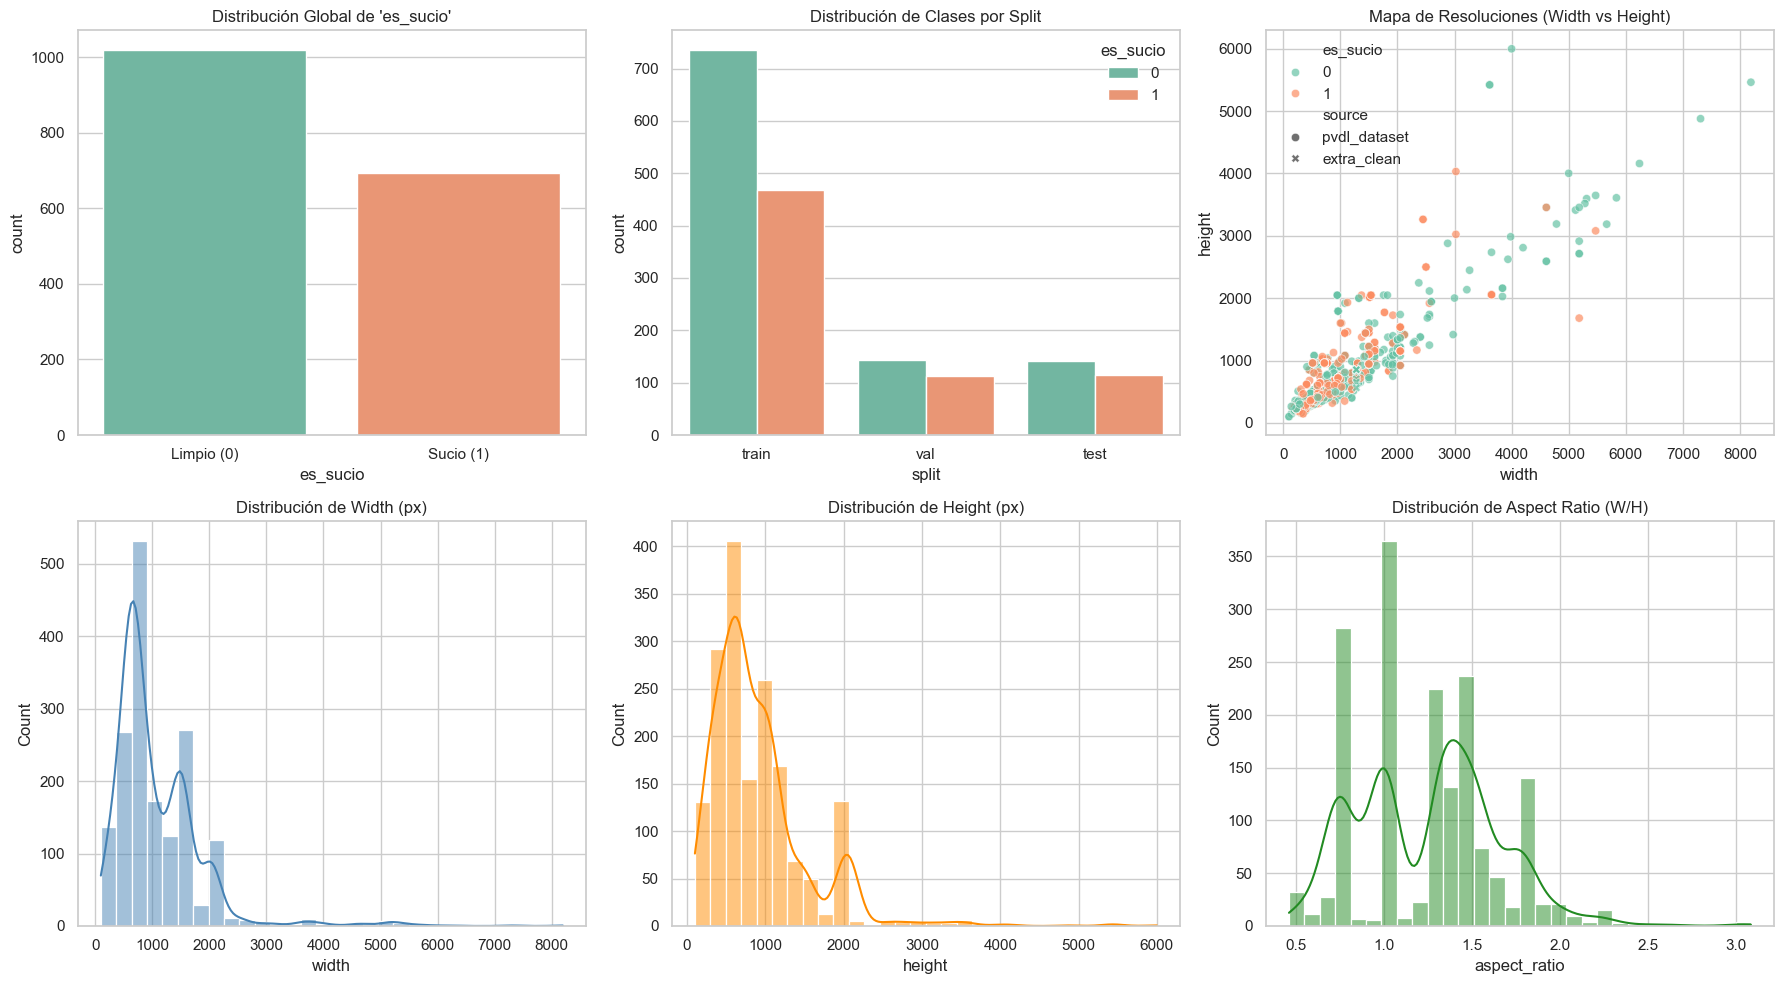

In [7]:
eda_plot_distributions(df)

=== ESTADÍSTICOS DE TAMAÑO Y OUTLIERS (IQR) ===
    Variable        Min        Q1     Mediana           Q3          Max  Outliers_IQR  %_Outliers
       width   100.0000    640.00    787.0000    1500.0000 8.192000e+03            42        2.45
      height   100.0000    500.00    720.0000    1101.0000 6.000000e+03           163        9.51
aspect_ratio     0.4611      1.00      1.3333       1.5006 3.085700e+00            13        0.76
    n_pixels 10000.0000 366518.75 691200.0000 1651500.0000 4.476109e+07            57        3.33


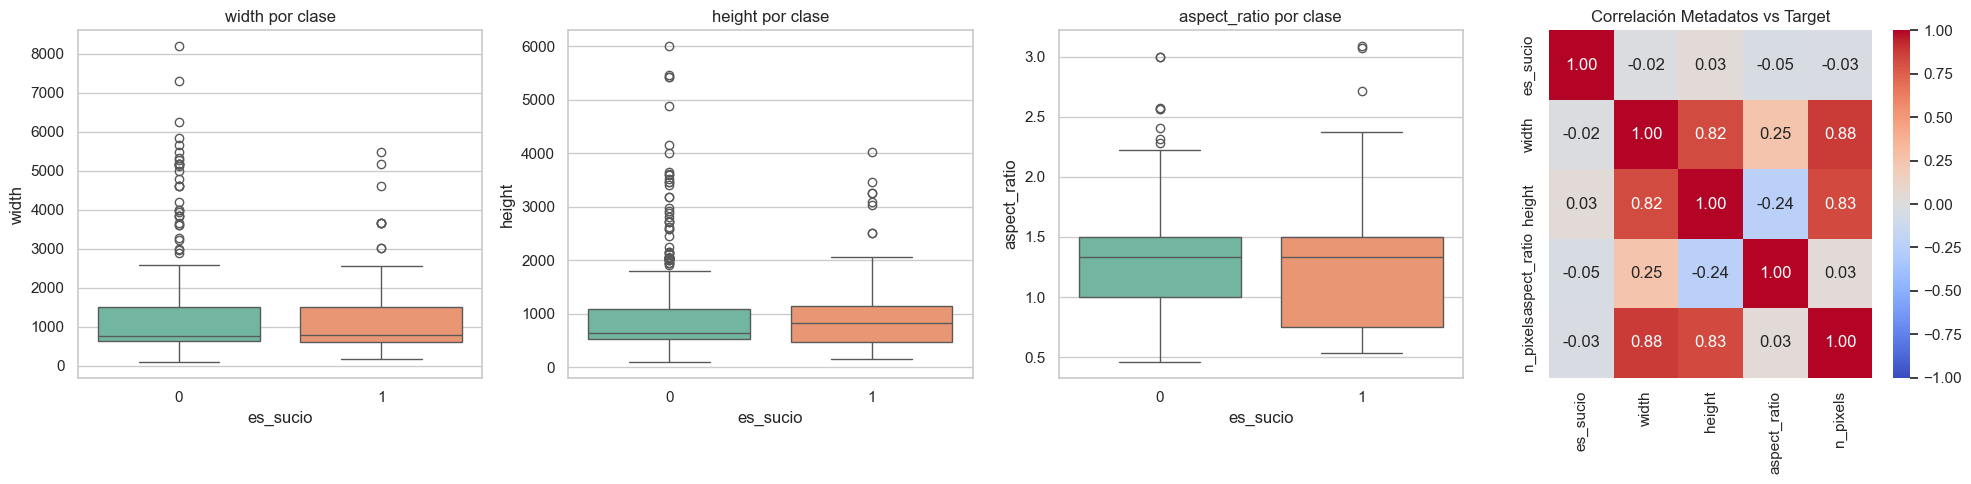

In [8]:
outlier_summary = eda_outliers_and_correlations(df)

Controlar Duplicados

In [9]:
check_duplicate_images(df)

Duplicados de fila en DataFrame: 0
Duplicados en 'ruta_imagen':     0
Imágenes idénticas (Hash MD5):   0


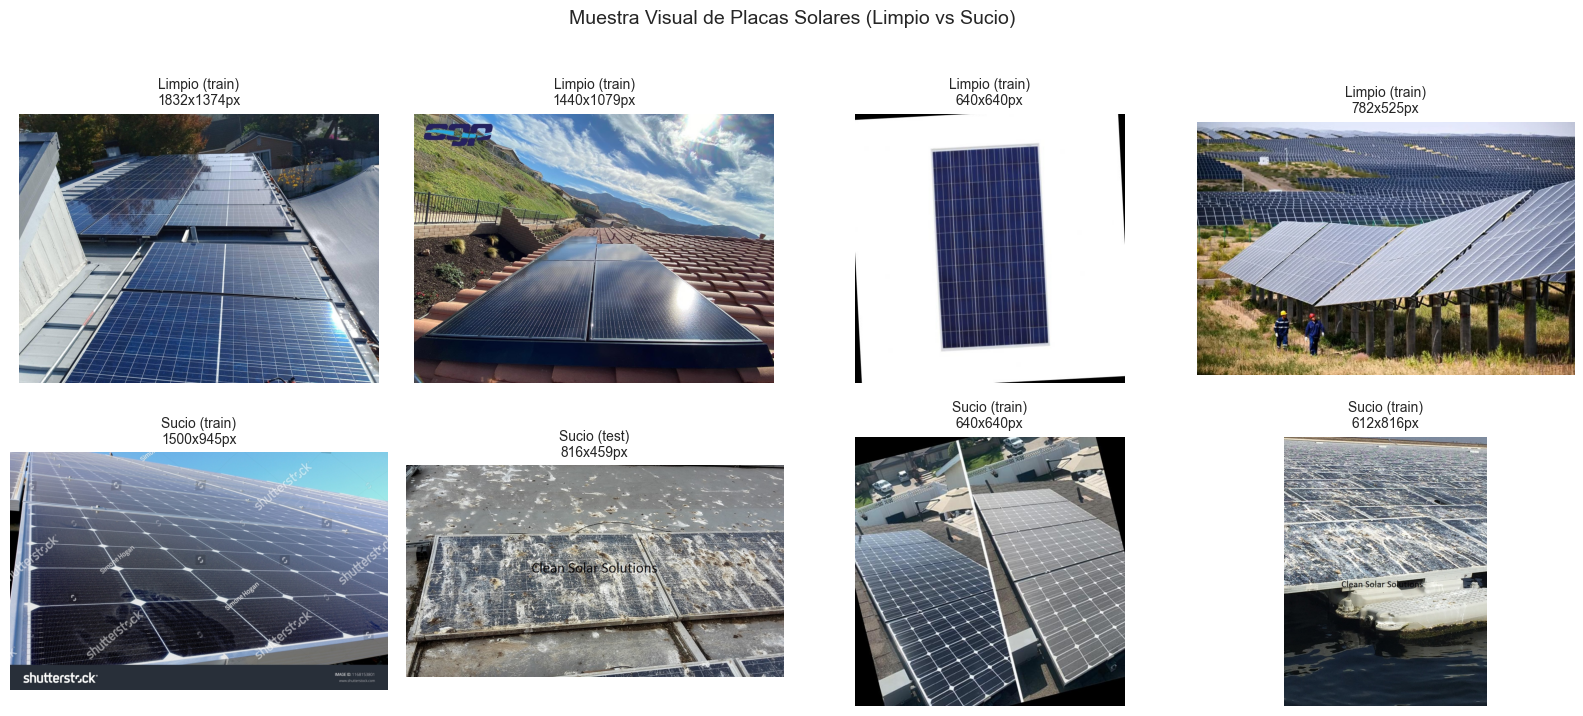

In [10]:
eda_plot_sample_images(df, n_per_class=4)

## 4. Preprocesamiento de Imágenes para Entrenamiento

Como demuestra la matriz de correlación del EDA, los metadatos geométricos (`width`, `height`, `aspect_ratio`) no tienen correlación con si la placa está limpia o sucia. Es imprescindible aplicar **transformaciones a las imágenes**:
- **(Deep Learning / PyTorch)**: Pipeline de `transforms` con redimensionado, *Data Augmentation* en `train` y normalización de canales.

### Preprocesamiento con Tensores y Data Augmentation (`PyTorch`)

In [11]:
from src.preprocessing import SolarImageDataset, build_dataloaders, denormalize_image, transform_image


Preprocesamiento Imágenes

In [12]:
from src.preprocessing import build_dataloaders


=== DATALOADERS LISTOS (Resolución: (224, 224), Batch: 32) ===
 - Train: 1204 muestras (38 batches)
 - Val:   255 muestras (8 batches)
 - Test:  255 muestras (8 batches)

=== COMPROBACIÓN DE TENSORES ===
Forma del lote de imágenes: torch.Size([32, 3, 224, 224])
Forma del lote de etiquetas: torch.Size([32])
Tipo de dato imágenes: torch.float32
Tipo de dato etiquetas: torch.int64


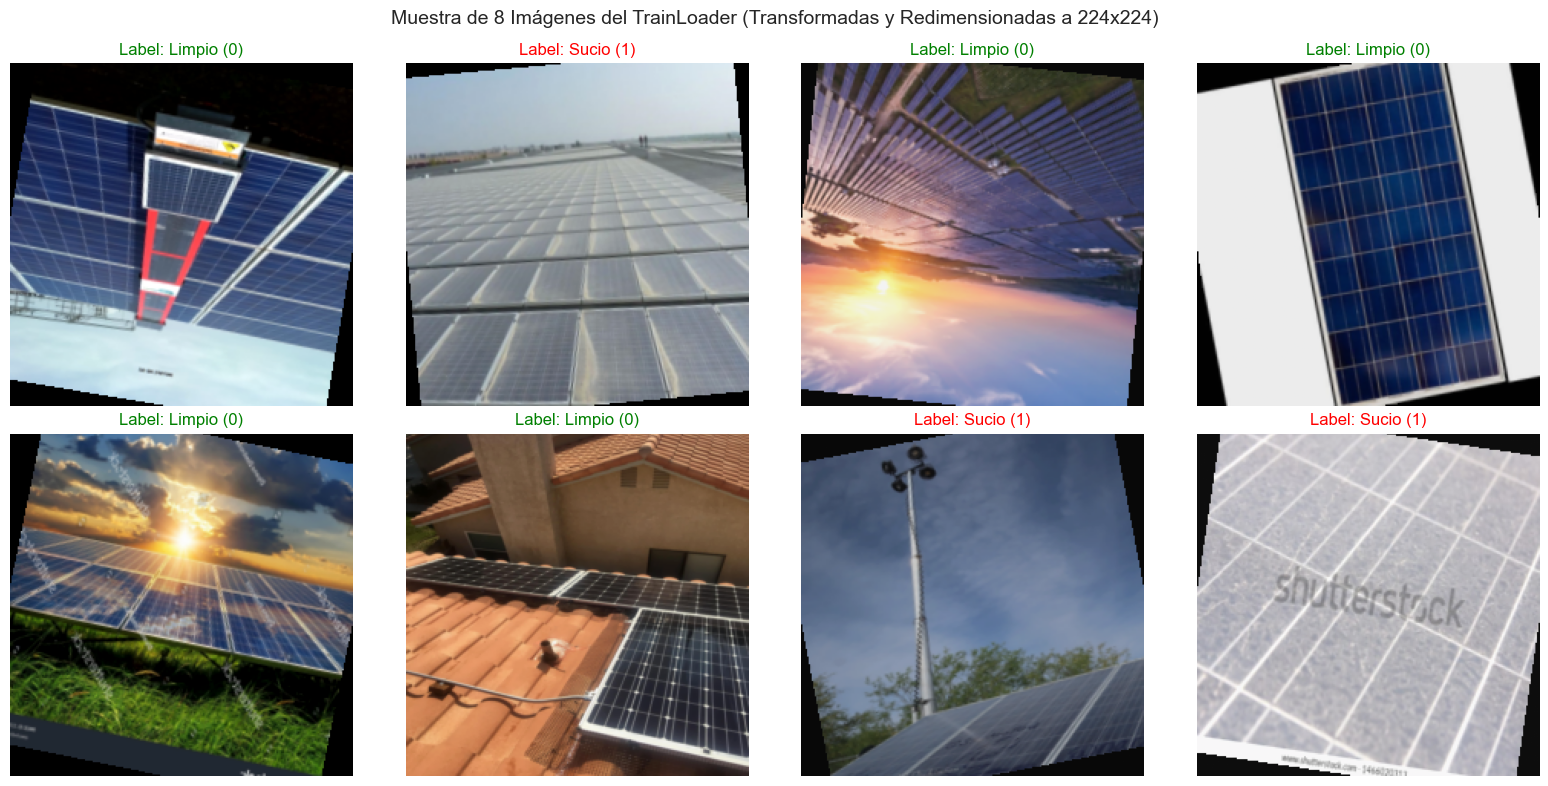

In [13]:
import matplotlib.pyplot as plt
from src.preprocessing import denormalize_image

# 1. Construir los DataLoaders
loaders = build_dataloaders(
    df=df,
    root_dir=PROJECT_ROOT,
    image_size=(224, 224),
    batch_size=32,
)

train_loader = loaders['train_loader']

# 2. Extraer un lote (batch) de prueba
images_batch, labels_batch = next(iter(train_loader))

print('\n=== COMPROBACIÓN DE TENSORES ===')
print('Forma del lote de imágenes:', images_batch.shape)
print('Forma del lote de etiquetas:', labels_batch.shape)
print('Tipo de dato imágenes:', images_batch.dtype)
print('Tipo de dato etiquetas:', labels_batch.dtype)

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i in range(8):
    img = denormalize_image(images_batch[i])
    label = labels_batch[i].item()
    texto_clase = 'Sucio (1)' if label == 1 else 'Limpio (0)'
    color_borde = 'red' if label == 1 else 'green'

    axes[i].imshow(img)
    axes[i].set_title(f'Label: {texto_clase}', color=color_borde, fontsize=12)
    axes[i].axis("off")

plt.suptitle(
    'Muestra de 8 Imágenes del TrainLoader (Transformadas y Redimensionadas a 224x224)',
    fontsize=14,
    y=0.98,
)
plt.tight_layout()
plt.show()
